# El EDA de mi proyecto

Es el mismo EDA que el del Titanic, con tus datos: las 9 preguntas, una detrás de otra. Al final se guardan los datos limpios en un CSV, que es el que lee la app.

Debajo de cada bloque hay una celda de texto para escribir lo que has visto y lo que has decidido, en una frase. Si no te acuerdas de cómo se hacía algo, mira titanic.ipynb, eda.ipynb o teoria_eda.ipynb.

## Mis datos

`https://huggingface.co/datasets/AhanaBiswas/WorldHappinessDataset2015-2023/resolve/main/World%20Happiness%20Dataset%202015-2023.csv`
Cada fila es un país con su puntuación y demás factores en determinados años.
¿Qué tienen los países más felices? ¿Cómo ha cambiado España?


## 0. Comprobación

In [792]:
import pandas as pd
import matplotlib
import numpy as np

print("Todo listo")

Todo listo


## 1. ¿Qué tengo?

Empieza por ver qué hay en la tabla.

**1.1** Carga tu CSV de la carpeta datos en una tabla con un nombre que diga qué es (como pisos o titanic) y enseña las primeras filas.

In [793]:
felicidad = pd.read_csv("felicidad.csv")
felicidad.head()


,country,region,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


**1.2** ¿Cuántas filas y columnas tiene?

In [794]:
print(felicidad.shape) #mostrar filas y columnas


(1367, 10)


**1.3** Mira el info(). ¿De qué tipo es cada columna? ¿Cuáles tienen huecos?

In [795]:
felicidad.info() #información de las columnas y tipos de datos

<class 'pandas.DataFrame'>
RangeIndex: 1367 entries, 0 to 1366
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       1367 non-null   str    
 1   region                        1367 non-null   str    
 2   happiness_score               1367 non-null   float64
 3   gdp_per_capita                1367 non-null   float64
 4   social_support                1367 non-null   float64
 5   healthy_life_expectancy       1366 non-null   float64
 6   freedom_to_make_life_choices  1367 non-null   float64
 7   generosity                    1367 non-null   float64
 8   perceptions_of_corruption     1366 non-null   float64
 9   year                          1367 non-null   int64  
dtypes: float64(7), int64(1), str(2)
memory usage: 145.8 KB


**1.4** Quédate con las columnas que te sirven para tu pregunta, o quita las que sobran.

In [796]:
#En un principio me quedo con todas las columnas.

**1.5** Si los nombres de las columnas están en inglés o son raros, ponles nombres en español.

In [797]:
felicidad.columns= ["pais","region","puntuacion_felicidad","pib_per_capita", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion", "año" ]
felicidad.head()


,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
0,Switzerland,Western Europe,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978,2015
1,Iceland,Western Europe,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145,2015
2,Denmark,Western Europe,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015
3,Norway,Western Europe,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503,2015
4,Canada,North America and ANZ,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015


Lo que he visto y lo que he decidido: Considero importantes todas las columnas por lo que no eliminaré ninguna. Solamente en corrupción falta un dato que lo rellenaré. Iba a eliminar las regiones pero creo que puede ser interesante utilizarla para obtener distintas estadísticas y gráficos.

## 2. ¿Qué me falta?

Cuenta lo que falta y decide qué haces con cada columna.

**2.1** Cuenta los huecos de cada columna.

In [798]:
felicidad.isna().sum() #cuenta los valores nulos de cada columna


pais                    0
region                  0
puntuacion_felicidad    0
pib_per_capita          0
apoyo_social            0
esperanza_vida          1
libertad                0
generosidad             0
corrupcion              1
año                     0
dtype: int64

**2.2** Calcula el porcentaje de huecos de cada columna.

In [799]:
porcentaje = felicidad.isna().sum() / len(felicidad) * 100
porcentaje.round(1)


pais                    0.0
region                  0.0
puntuacion_felicidad    0.0
pib_per_capita          0.0
apoyo_social            0.0
esperanza_vida          0.1
libertad                0.0
generosidad             0.0
corrupcion              0.1
año                     0.0
dtype: float64

**2.3** Decide qué haces con cada columna que tenga huecos: quitar la columna, quitar esas filas o rellenarlos. Hazlo.

In [800]:
felicidad["esperanza_vida"]= felicidad["esperanza_vida"].fillna(felicidad["esperanza_vida"].median()) # rellenamos los valores NaN de la columna esperanza_vida con la mediana de la columna esperanza_vida    
felicidad["esperanza_vida"].isna().sum() # comprobamos que ya no hay valores NaN en la columna esperanza_vida

felicidad["corrupcion"]= felicidad["corrupcion"].fillna(felicidad["corrupcion"].median()) # rellenamos los valores NaN de la columna corrupcion con la mediana de la columna corrupcion
felicidad["corrupcion"].isna().sum() # comprobamos que ya no hay valores NaN en la columna corrupcion


np.int64(0)

**2.4** Comprueba que ya no quedan huecos, o que los que quedan los dejas a propósito.

In [801]:
felicidad.isna().sum() # comprobamos que ya no hay valores NaN en ninguna columna

pais                    0
region                  0
puntuacion_felicidad    0
pib_per_capita          0
apoyo_social            0
esperanza_vida          0
libertad                0
generosidad             0
corrupcion              0
año                     0
dtype: int64

**2.5** Mira con value_counts las columnas de texto. ¿Hay algún hueco disfrazado, como "Unknown", "-" o "N/A"?

In [802]:
felicidad[["pais","region"]].value_counts() #vemos los países y regiones que hay en el dataset


pais                region                      
Cyprus              Western Europe                  11
Switzerland         Western Europe                   9
Iceland             Western Europe                   9
Denmark             Western Europe                   9
Norway              Western Europe                   9
                                                    ..
Somaliland Region   Africa                           1
Congo               Sub-Saharan Africa               1
Eswatini            Sub-Saharan Africa               1
State of Palestine  Middle East and North Africa     1
Turkiye             Middle East and North Africa     1
Name: count, Length: 171, dtype: int64

Lo que he visto y lo que he decidido: En este caso al ver que Afghanistan tenía 0.0000 en apoyo social y libertad, puede haber varias filas con 0.0000. He decidido convertir los 0.000 en valores nulos NaN y después rellenar cada NaN con la mediana específica de su propia región geográfica.

## 3. ¿Hay filas repetidas?

Comprueba si hay algo contado dos veces.

**3.1** ¿Cuántas filas repetidas hay?

In [803]:
print("Filas repetidas", felicidad.duplicated().sum(), "en felicidad") # contamos las filas duplicadas en felicidad



Filas repetidas 0 en felicidad


**3.2** Si tienes una columna que identifica cada fila (un id, un nombre), ¿hay algún valor repetido?

In [804]:
print("Paises repetidos", felicidad["pais"].duplicated().sum(), "en felicidad") # contamos los paises duplicados en felicidad



Paises repetidos 1196 en felicidad


**3.3** Decide si las quitas, y hazlo. Si no son la misma fila, no se quitan.

In [805]:
#Decido no quitar o eliminar porque en este caso aunque se repitan los paises, cada vez es un año diferente, por lo que no es un error, es información diferente.


Lo que he visto y lo que he decidido: Cuento las filas duplicadas de paises y ya de antemano sabía que se repetirían muchas filas pero al ser del año 2015 al 2023 cada vez que se repite el nombre del país es por tener distinta información sobre la felicidad en esos años, por lo tanto decido mantener todo lo que tenía hasta ahora.

## 4. ¿Cómo son los números?

Mira los números con el describe, la media, la mediana y un histograma.

**4.1** Haz el describe. ¿Qué te llama la atención?

In [806]:
felicidad.describe() #estadísticas de las columnas numéricas

,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
count,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000
mean,5.441086,1.019422,1.045334,0.584064,0.450771,0.196260,0.132249,2018.903438
std,1.117909,0.453703,0.331163,0.245029,0.156733,0.113301,0.112518,2.561006
min,1.859000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2015.000000
25%,4.599500,0.696326,0.832022,0.402554,0.356000,0.115000,0.056884,2017.000000
50%,5.440000,1.043000,1.083000,0.612830,0.467610,0.182700,0.097000,2019.000000
75%,6.256300,1.338473,1.299985,0.777602,0.568685,0.252858,0.165890,2021.000000
max,7.842000,2.209000,1.644000,1.141000,0.772000,0.838075,0.587000,2023.000000


In [807]:
#Me llama la atención posibles datos nulos que no se han detectado, por lo que voy a comprobar si hay valores 0.0 en las columnas numéricas, ya que podrían ser datos nulos que no se han detectado.
# Cuenta cuántas veces aparece exactamente el valor 0.0 en cada columna numérica

(felicidad == 0.0).sum() #quiero saber si hay valores 0.0 en las columnas numéricas, ya que podrían ser datos nulos que no se han detectado.

pais                     0
region                   0
puntuacion_felicidad     0
pib_per_capita           9
apoyo_social             9
esperanza_vida           9
libertad                 9
generosidad              9
corrupcion              10
año                      0
dtype: int64

In [808]:
# 1. Primero convertimos los 0.0 sospechosos en NaN (valores nulos reales)

felicidad["apoyo_social"] = felicidad["apoyo_social"].replace(0.0, np.nan)
felicidad["libertad"] = felicidad["libertad"].replace(0.0, np.nan)
felicidad["pib_per_capita"] = felicidad["pib_per_capita"].replace(0.0, np.nan)
felicidad["esperanza_vida"] = felicidad["esperanza_vida"].replace(0.0, np.nan)
felicidad["generosidad"] = felicidad["generosidad"].replace(0.0, np.nan)
felicidad["corrupcion"] = felicidad["corrupcion"].replace(0.0, np.nan)

# 2. Rellenamos cada NaN con la mediana específica de su propia región geográfica

felicidad["apoyo_social"] = felicidad["apoyo_social"].fillna(felicidad.groupby("region")["apoyo_social"].transform("median"))
felicidad["libertad"] = felicidad["libertad"].fillna(felicidad.groupby("region")["libertad"].transform("median"))
felicidad["pib_per_capita"] = felicidad["pib_per_capita"].fillna(felicidad.groupby("region")["pib_per_capita"].transform("median"))
felicidad["esperanza_vida"] = felicidad["esperanza_vida"].fillna(felicidad.groupby("region")["esperanza_vida"].transform("median"))
felicidad["generosidad"] = felicidad["generosidad"].fillna(felicidad.groupby("region")["generosidad"].transform("median"))
felicidad["corrupcion"] = felicidad["corrupcion"].fillna(felicidad.groupby("region")["corrupcion"].transform("median"))

felicidad.describe() #estadísticas de las columnas numéricas

,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
count,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000,1367.000000
mean,5.441086,1.023525,1.050593,0.585963,0.453732,0.197654,0.132609,2018.903438
std,1.117909,0.447568,0.320693,0.241585,0.152444,0.112245,0.112183,2.561006
min,1.859000,0.015300,0.058000,0.005565,0.005890,0.001990,0.000830,2015.000000
25%,4.599500,0.704160,0.832022,0.402554,0.359975,0.116955,0.057000,2017.000000
50%,5.440000,1.043000,1.083000,0.612830,0.468660,0.183860,0.097000,2019.000000
75%,6.256300,1.338473,1.299985,0.777602,0.568685,0.252858,0.165890,2021.000000
max,7.842000,2.209000,1.644000,1.141000,0.772000,0.838075,0.587000,2023.000000


**4.2** Saca la media y la mediana de la columna de números más importante para tu pregunta. ¿Se parecen?

In [809]:
print("Puntuación media de la felicidad:", round(felicidad["puntuacion_felicidad"].mean(), 1)) # puntuación media de la felicidad
print("Puntuación mediana de la felicidad:", round(felicidad["puntuacion_felicidad"].median(), 1)) # puntuación mediana de la felicidad

print(felicidad[felicidad["pais"] == "Spain"]) # mostramos los datos de España

Puntuación media de la felicidad: 5.4
Puntuación mediana de la felicidad: 5.4
       pais          region  puntuacion_felicidad  pib_per_capita  \
35    Spain  Western Europe                6.3290        1.230110   
194   Spain  Western Europe                6.3610        1.342530   
348   Spain  Western Europe                6.4030        1.384398   
505   Spain  Western Europe                6.3100        1.251000   
655   Spain  Western Europe                6.3540        1.286000   
809   Spain  Western Europe                6.4009        1.230535   
961   Spain  Western Europe                6.4910        1.375000   
1112  Spain  Western Europe                6.4760        1.808000   
1261  Spain  Western Europe                6.4360        1.798000   

      apoyo_social  esperanza_vida  libertad  generosidad  corrupcion   año  
35        1.313790        0.955620  0.459510     0.182270    0.063980  2015  
194       1.129450        0.878960  0.375450     0.176650    0.061370  2016

**4.3** Dibuja su histograma.

<Axes: title={'center': 'Distribución de la puntuación de felicidad'}, ylabel='Frequency'>

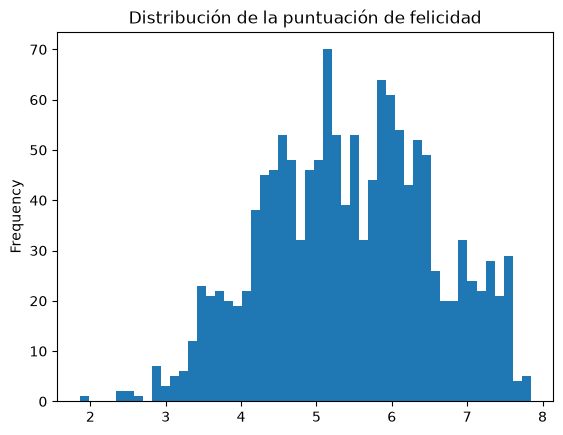

In [810]:
felicidad["puntuacion_felicidad"].plot(kind="hist", bins=50, title="Distribución de la puntuación de felicidad") # histograma de la puntuación de felicidad



**4.4** Haz lo mismo con otra columna de números.

<Axes: title={'center': 'Distribución del PIB per cápita'}, ylabel='Frequency'>

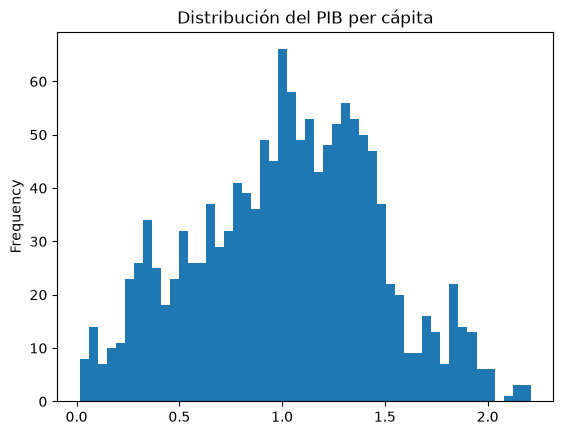

In [811]:
felicidad["pib_per_capita"].plot(kind="hist", bins=50, title="Distribución del PIB per cápita") # histograma del PIB per cápita



Lo que he visto y lo que he decidido:
Al dar la media y mediana de la puntuación de la felicidad 5.4 se ve que no hay ni por arriba ni por debajo valores extremos y son datos bastante equilibrados.

Tener el PIB del pais alto en el caso de España ayuda para tener más felicidad pero se ve que la corrución hace que baje o equilibre bastante la puntuación. Por lo que teniendo algo menos de Pib pero no teniendo tanta corrupción sube o nivela bastante la felicidad. En los demás valores aunque sean distintos en los años no aprecio que se note tanto en la puntuación final, esas 2 características son las que veo que mas influyen.

## 5. ¿Hay algo raro?

Busca los valores extremos y decide si son errores o casos reales.

**5.1** Enseña las 5 filas con el valor más alto de tu columna principal.

In [812]:
felicidad.sort_values("puntuacion_felicidad", ascending=False).head(5) # mostramos los 5 países con mayor puntuación de felicidad


,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
935,Finland,Western Europe,7.8420,1.44600,1.106000,0.741000,0.691000,0.12400,0.481000,2021
1084,Finland,Western Europe,7.8210,1.89200,1.258000,0.775000,0.736000,0.10900,0.534000,2022
782,Finland,Western Europe,7.8087,1.28519,1.499526,0.961271,0.662317,0.15967,0.477857,2020
1230,Finland,Western Europe,7.8040,1.88800,1.585000,0.535000,0.772000,0.12600,0.535000,2023
626,Finland,Western Europe,7.7690,1.34000,1.587000,0.986000,0.596000,0.15300,0.393000,2019


**5.2** Y las 5 con el más bajo. ¿Hay ceros o valores imposibles?

In [813]:
felicidad.sort_values("puntuacion_felicidad", ascending=True).head(5) # mostramos los 5 países con menor puntuación de felicidad


,pais,region,puntuacion_felicidad,pib_per_capita,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,año
1366,Afghanistan,South Asia,1.8590,0.645000,0.774500,0.087000,0.499769,0.093000,0.059000,2023
1365,Lebanon,Middle East and North Africa,2.3920,1.417000,0.476000,0.398000,0.123000,0.061000,0.027000,2023
1229,Afghanistan,South Asia,2.4040,0.758000,0.774500,0.289000,0.499769,0.089000,0.005000,2022
1083,Afghanistan,South Asia,2.5230,0.370000,0.774500,0.126000,0.499769,0.122000,0.010000,2021
934,Afghanistan,South Asia,2.5669,0.300706,0.356434,0.266052,0.499769,0.135235,0.001226,2020


**5.3** Haz el diagrama de caja de esa columna.

<Axes: title={'center': 'Distribución de la puntuación de felicidad'}>

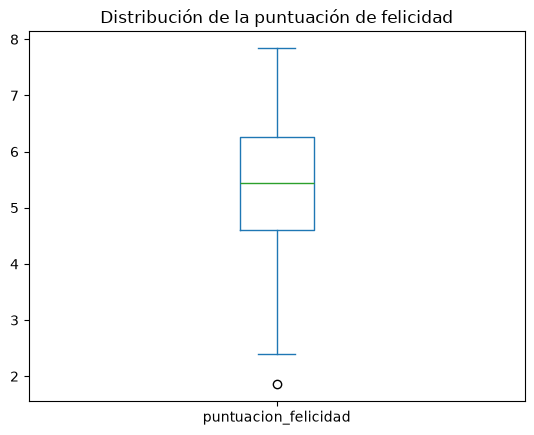

In [814]:
felicidad["puntuacion_felicidad"].plot(kind="box", title="Distribución de la puntuación de felicidad") # histograma de la puntuación de felicidad



**5.4** Decide qué haces con cada valor raro: si es un error, corrígelo o quítalo; si es real, se queda.

Lo que he visto y lo que he decidido:

En el paso 4 he actuado al ver que seguía habiendo datos extraños con muchos 0.00000 en varias columnas y ahí he decidido actuar y limpiar esos datos convirtiendo primero los 0.0000 en NaN Y después a esos NaN replazandolos por la mediana según la región en la que estuvieran.

## 6. ¿Qué hay más?

Cuántas filas hay de cada tipo.

**6.1** Haz el value_counts de la columna de texto más importante, en número y en porcentaje.

In [815]:
pd.DataFrame({"Cantidad": felicidad["pais"].value_counts(),"Porcentaje (%)": felicidad["pais"].value_counts(normalize=True) * 100,})# Creamos una tabla que junta el recuento y el porcentaje (%)

,Cantidad,Porcentaje (%)
pais,,
Cyprus,11,0.804682
Switzerland,9,0.658376
Iceland,9,0.658376
Denmark,9,0.658376
Norway,9,0.658376
...,...,...
Somaliland Region,1,0.073153
Congo,1,0.073153
Eswatini,1,0.073153


#Añado los 35 países que más se repiten

In [816]:
pd.DataFrame( {"Cantidad": felicidad["pais"].value_counts().head(35),"Porcentaje (%)": felicidad["pais"].value_counts(normalize=True).head(35) * 100,})# Creamos una tabla que junta el recuento y el porcentaje (%)


,Cantidad,Porcentaje (%)
pais,,
Cyprus,11,0.804682
Switzerland,9,0.658376
Iceland,9,0.658376
Denmark,9,0.658376
Norway,9,0.658376
Canada,9,0.658376
Finland,9,0.658376
Netherlands,9,0.658376
Sweden,9,0.658376


**6.2** Dibújalo en barras.

<Axes: title={'center': 'Top 10 países con más registros en el dataset'}, xlabel='Países', ylabel='Cantidad de registros'>

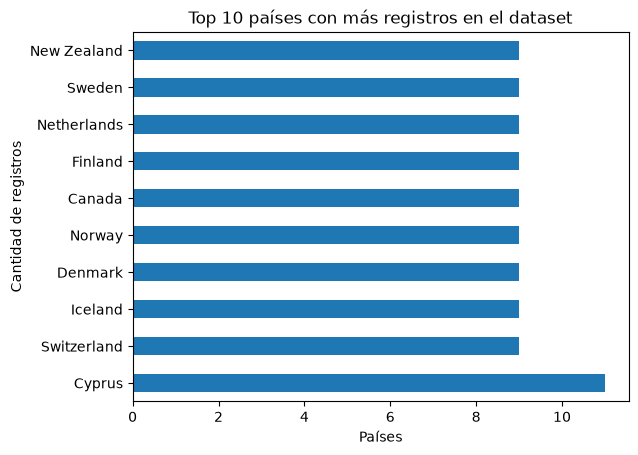

In [817]:
felicidad["pais"].value_counts().head(10).plot(kind="barh",title="Top 10 países con más registros en el dataset", xlabel="Países", ylabel="Cantidad de registros")

Lo que he visto y lo que he decidido: Hago un value_counts para ver cuántas veces se repite cada país y veo que en general la mayoría se repiten muchas veces lo que hace que en general los datos a la hora de tener en cuenta el progreso de la felicidad año a año sea más real. Por otra parte al haber tantos países solo cojo para la gráfica unos pocos porque sino queda fea.

## 7. ¿Cambia algo de un grupo a otro?

Aquí es donde suelen salir los hallazgos.

**7.1** Con groupby, calcula la media o la mediana de tu columna principal en cada grupo.

In [818]:
felicidad.groupby("region")["puntuacion_felicidad"].agg(["mean", "median"]) #con agg hacemos que aparezca en una sola tabla la media y la mediana y quede mas limpio y bonito.


,mean,median
region,,
Africa,5.057000,5.05700
Central and Eastern Europe,5.585753,5.60925
Commonwealth of Independent States,5.639041,5.70100
East Asia,5.732150,5.83650
Latin America and Caribbean,5.993861,6.09550
Middle East and North Africa,5.275104,5.13180
North America and ANZ,7.176058,7.22540
South Asia,4.473264,4.51600
Southeast Asia,5.370429,5.34200


**7.2** Haz otra comparación con otra columna de grupos.

In [819]:
felicidad.groupby("region")["pib_per_capita"].agg(["mean", "median"]) #con agg hacemos lo mismo que en la celda anterior, pero con la columna pib_per_capita


,mean,median
region,,
Africa,0.222025,0.222025
Central and Eastern Europe,1.189778,1.161730
Commonwealth of Independent States,0.892170,0.962235
East Asia,1.350287,1.372373
Latin America and Caribbean,1.027571,1.022694
Middle East and North Africa,1.162901,1.117580
North America and ANZ,1.501825,1.419353
South Asia,0.732813,0.726884
Southeast Asia,1.015817,0.960450


**7.3** Antes de sacar conclusiones, mira cuántas filas tiene cada grupo. ¿Hay alguno con muy pocas?

In [820]:
felicidad.groupby("region").size() # Muestra cuántas filas tiene cada grupo de región

region
Africa                                  2
Central and Eastern Europe            214
Commonwealth of Independent States     44
East Asia                              54
Latin America and Caribbean           190
Middle East and North Africa          161
North America and ANZ                  36
South Asia                             61
Southeast Asia                         80
Sub-Saharan Africa                    337
Western Europe                        188
dtype: int64

Análisis de valores agregados por región:

-Evaluación métrica: Se calculó la media y la mediana de la puntuación de felicidad y del PIB per cápita agrupados por región para identificar patrones geográficos.

-Control de calidad de la muestra: Al auditar el tamaño de cada grupo mediante .size(), se detectó una gran disparidad: mientras la mayoría de regiones concentran entre 36 y 337 registros, la categoría regionAfrica cuenta únicamente con 2 registros.


## 8. ¿Van juntas dos columnas?

Comprueba si dos columnas de números tienen relación.

**8.1** Calcula la correlación entre dos columnas de números.

In [821]:
#Hago la correlación de todos los factores respecto a la puntuación de felicidad
factores = ["pib_per_capita", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion"]

for factor in factores:
    corr = felicidad["puntuacion_felicidad"].corr(felicidad[factor])
    print(f"Correlación Felicidad - {factor}: {corr:.2f}")

Correlación Felicidad - pib_per_capita: 0.73
Correlación Felicidad - apoyo_social: 0.63
Correlación Felicidad - esperanza_vida: 0.68
Correlación Felicidad - libertad: 0.55
Correlación Felicidad - generosidad: 0.08
Correlación Felicidad - corrupcion: 0.42


**8.2** Haz el gráfico de puntos de esas dos columnas.

<Axes: xlabel='puntuacion_felicidad', ylabel='pib_per_capita'>

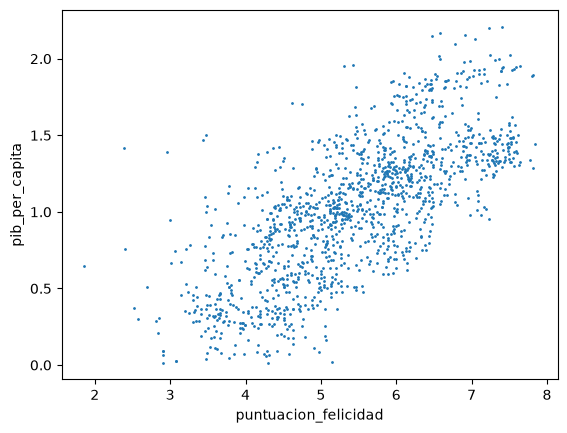

In [822]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="pib_per_capita", s=1) # scatter plot de puntuación de felicidad vs PIB per cápita

<Axes: xlabel='puntuacion_felicidad', ylabel='apoyo_social'>

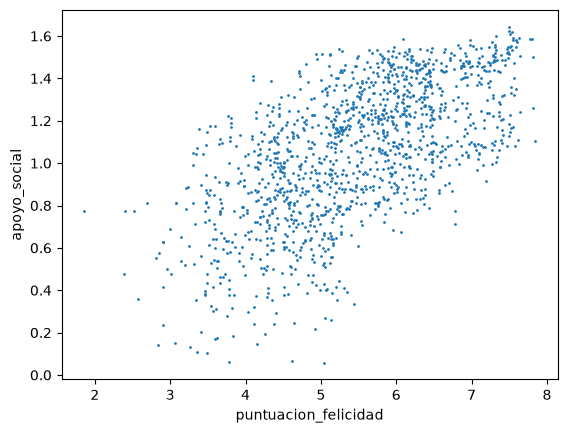

In [823]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="apoyo_social", s=1) # scatter plot de puntuación de felicidad vs apoyo social

<Axes: xlabel='puntuacion_felicidad', ylabel='esperanza_vida'>

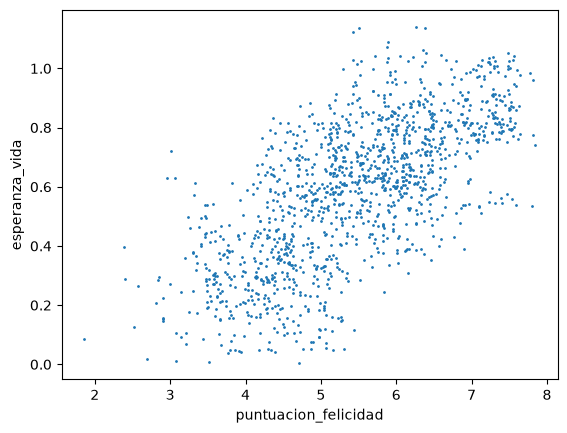

In [824]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="esperanza_vida", s=1) # scatter plot de puntuación de felicidad vs esperanza de vida

<Axes: xlabel='puntuacion_felicidad', ylabel='libertad'>

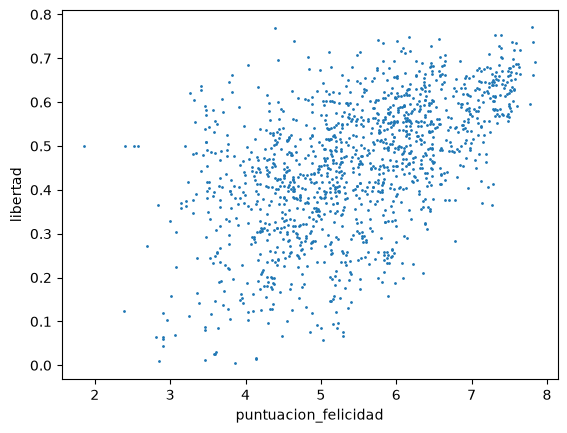

In [825]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="libertad", s=1) # scatter plot de puntuación de felicidad vs libertad

<Axes: xlabel='puntuacion_felicidad', ylabel='corrupcion'>

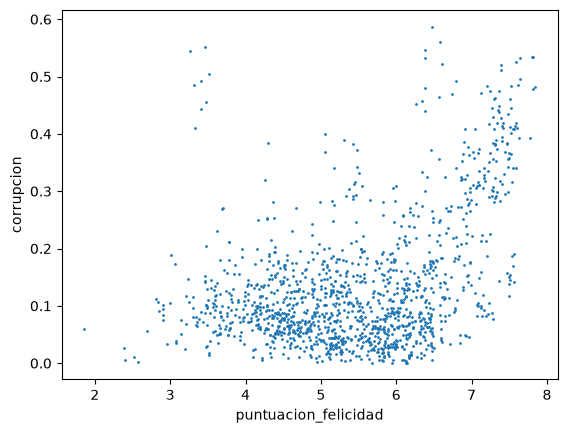

In [826]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="corrupcion", s=1) # scatter plot de puntuación de felicidad vs corrupcion

<Axes: xlabel='puntuacion_felicidad', ylabel='generosidad'>

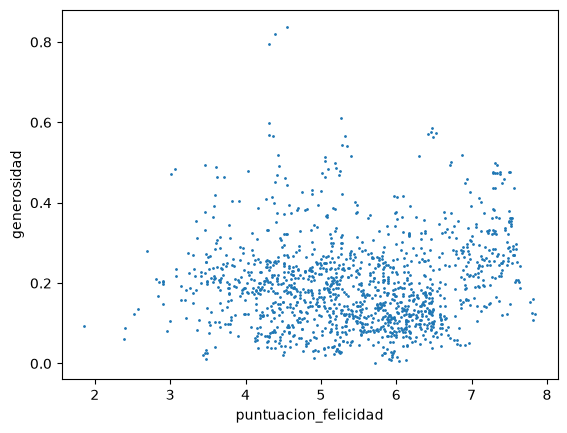

In [827]:
felicidad.plot(kind="scatter", x= "puntuacion_felicidad", y="generosidad", s=1) # scatter plot de puntuación de felicidad vs generosidad

In [829]:
felicidad.info()

<class 'pandas.DataFrame'>
RangeIndex: 1367 entries, 0 to 1366
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   pais                  1367 non-null   str    
 1   region                1367 non-null   str    
 2   puntuacion_felicidad  1367 non-null   float64
 3   pib_per_capita        1367 non-null   float64
 4   apoyo_social          1367 non-null   float64
 5   esperanza_vida        1367 non-null   float64
 6   libertad              1367 non-null   float64
 7   generosidad           1367 non-null   float64
 8   corrupcion            1367 non-null   float64
 9   año                   1367 non-null   int64  
dtypes: float64(7), int64(1), str(2)
memory usage: 145.8 KB


·Lo que he visto y lo que he decidido:
-Correlación entre la puntuación y el PIB per cápita (0.73):
    Fuerte correlación positiva: Al estar por encima de 0.70, nos indica que hay una relación directa muy clara entre la riqueza económica de un país y los niveles de felicidad que reportan sus ciudadanos.
    En la práctica: Nos demuestra que, aunque el dinero no lo es todo, los países económicamente más prósperos tienden de forma muy consistente a ocupar los puestos más altos de felicidad en el ranking mundial.

-Correlación entre la puntuación y la esperanza de vida (0.68):
    Fuerte relación positiva: Al igual que pasa con el PIB, nos muestra que la salud física y la longevidad caminan de la mano de la felicidad de forma muy clara.
    En la práctica: Los países donde sus ciudadanos disfrutan de una mayor esperanza de vida (lo que implica mejores sistemas de salud y calidad de vida general) son también los que registran un mayor nivel de bienestar.

-Correlación entre la puntuación y el apoyo social (0.63):
    Fuerte relación positiva: Se sitúa muy cerca de los indicadores de salud y economía, reflejando que el factor humano y comunitario es un pilar fundamental.
    En la práctica: Destaca la importancia vital de tener una red de seguridad (amigos, familia o instituciones a las que recurrir en caso de necesidad). Saber que no se está solo ante las dificultades es un motor clave de la felicidad nacional.

-Correlación entre la puntuación y la libertad (0.55):
    Correlación moderada-positiva: Muestra una tendencia clara y saludable que demuestra que los derechos y la autonomía importan.
    En la práctica: La capacidad de los ciudadanos para tomar decisiones libres sobre sus propias vidas (estudio, trabajo, estilo de vida) aporta un valor significativo a la satisfacción general con la vida.

-Correlación entre la puntuación y la corrupción (0.42):
    Correlación moderada-baja: Se sitúa un escalón por debajo en cuanto a fuerza lineal, pero sigue manteniendo una tendencia positiva.
    En la práctica: Nos indica que la percepción de la corrupción (o la confianza institucional) juega un papel en la estabilidad emocional de la sociedad, aunque su impacto directo a gran escala es algo menos determinante que la economía o la salud. Aún así, los países con menor corrupción percibida tienden a registrar mejores puntuaciones.

-Correlación entre la puntuación y la generosidad (0.08):
    Correlación nula / insignificante: Prácticamente no existe relación lineal a nivel macroeconómico.
    En la práctica: Es una gran conclusión analítica. Aunque el altruismo y la generosidad son valores éticos fundamentales a nivel individual, medidos a escala de países no sirven para predecir si una nación va a tener una puntuación alta o baja de felicidad (la economía, la salud y la red de apoyo mandan con muchísima más fuerza).

## 9. ¿Qué he aprendido?

**9.1** Haz doble clic en la celda de abajo y escribe tus tres hallazgos, cada uno en una frase con un número. Añade otra con lo que has quitado o cambiado en los datos. Esto es lo que irá en el README y en la presentación.

1. Los pilares fundamentales y el "efecto amortiguador" de la economía
El hallazgo: El PIB per cápita (0.73) y la esperanza de vida (0.68) actúan como los dos grandes motores universales de la felicidad.

La conclusión: Una economía altamente desarrollada y unos servicios de salud sólidos tienen la capacidad de amortiguar deficiencias institucionales. Es decir, los ciudadanos de países prósperos logran mantener niveles elevados de bienestar percibido a pesar de que la corrupción o la desconfianza institucional sean notablemente más altas, demostrando que el bienestar material pesa mucho en el balance diario.

2. La inercia y estabilidad del bienestar en economías consolidadas (El caso de España)
El hallazgo: Al analizar la evolución temporal de España (2015-2023), el índice de felicidad se muestra inusualmente estanco y estable (franja constante de 6.3 a 6.4 puntos).

La conclusión: El bienestar subjetivo en sociedades desarrolladas no responde de forma directa a las fluctuaciones coyunturales del PIB o a crisis económicas a corto plazo. Se trata de una métrica estructural que responde a factores culturales, redes de apoyo y estilos de vida consolidados a largo plazo, mostrando una gran resiliencia frente a los vaivenes macroeconómicos anuales.

3. La fractura estructural y la desigualdad sistémica global
El hallazgo: La profunda brecha geográfica que separa a bloques como North America & ANZ (~7.18) o Western Europe (~6.81) frente a Sub-Saharan Africa (~4.29) o South Asia (~4.47), con una diferencia de casi 3 puntos completos.

La conclusión: La mínima discrepancia estadística entre la media y la mediana en cada bloque confirma que no estamos ante casos aislados o excepciones geográficas, sino ante una realidad sistémica. La felicidad a escala global está directamente condicionada por el acceso estructural a las oportunidades, el desarrollo humano y la estabilidad institucional compartida a escala regional.


Evolución de lo que hago con los datos:


1º En 2 columnas observo que hay 1 hueco por cada una.

2º Traduzco el nombre de las columnas a castellano.

3º Relleno el hueco de cada columna con la mediana de su columna correspondiente.

4º Al mirar con value_counts observo que hay países que se repiten bastantes veces. 

5º Hay 1196 filas repetidas en la columna "País" pero al ser de años distintos no elimino ninguna.

6º Ahora hago un describe de todo y observo en valores mínimos de muchas columnas que hay valores de 0.0000. Por lo que con estas columnas decido convertir los 0.0000 que hay en todas las filas en valores NaN Y así después relleno cada NaN con la mediana específica de su propia región geográfica.

## 10. Guardar los datos limpios

**10.1** Guarda la tabla limpia en datos/datos_limpios.csv con to_csv y index=False. Es el archivo que lee la app.

Resultado esperado: un archivo nuevo, datos_limpios.csv, en la carpeta datos.

In [830]:
felicidad.to_csv(r"C:\Users\User\Desktop\Bootcamp\Proyecto M-1\felicidad_limpio.csv",index=False,)